In [28]:
import pandas as pd  # Daten verarbeiten

data = pd.read_csv("../Data/BNPL_Financial_Default_Risk_Dataset.csv")# CSV-Datei laden

print(data.head())# Erste 5 Zeilen anzeigen


  Customer_ID  Age Employment_Status  Income_USD  Credit_Score  \
0      C00001   29          Employed     73405.0         637.0   
1      C00002   64          Employed     53732.0         815.0   
2      C00003   26        Freelancer     69930.0         723.0   
3      C00004   19          Employed     96941.0         716.0   
4      C00005   55           Student     15959.0         675.0   

   Total_BNPL_Active_Loans  Total_BNPL_Debt_USD Late_Payment_History  \
0                        2                  193                   No   
1                        0                    0                   No   
2                        2                  273                   No   
3                        3                  421                   No   
4                        2                  145                   No   

  Shopping_Category_Most_Frequent  Average_Transaction_Value_USD Default_Risk  
0                         Fashion                            118          Low  
1         

In [6]:
print(data.shape)             # Anzahl der Zeilen und Spalten

(10000, 11)


In [29]:
print(data.info())            # Datentypen und fehlende Werte

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Customer_ID                      10000 non-null  str    
 1   Age                              10000 non-null  int64  
 2   Employment_Status                10000 non-null  str    
 3   Income_USD                       9695 non-null   float64
 4   Credit_Score                     9702 non-null   float64
 5   Total_BNPL_Active_Loans          10000 non-null  int64  
 6   Total_BNPL_Debt_USD              10000 non-null  int64  
 7   Late_Payment_History             10000 non-null  str    
 8   Shopping_Category_Most_Frequent  10000 non-null  str    
 9   Average_Transaction_Value_USD    10000 non-null  int64  
 10  Default_Risk                     10000 non-null  str    
dtypes: float64(2), int64(4), str(5)
memory usage: 859.5 KB
None


#Kennzahl	Erklärung
#count	    Anzahl der vorhandenen Werte
#mean	    Durchschnitt
#std	        Standardabweichung – wie stark Werte streuen
#min	        Kleinster Wert
#25 %        der Werte liegen bei oder unter diesem Wert
#50%	        Median – die Hälfte der Werte liegt darunter oder ist gleich groß
#75%	        der Werte liegen bei oder unter diesem Wert
#max	        Größter Wert

In [12]:

print(data.describe())        # Statistische Kennzahlen

print("###################################################")

print(data.columns.tolist())  # Alle Spaltennamen

                Age     Income_USD  Credit_Score  Total_BNPL_Active_Loans  \
count  10000.000000    9695.000000   9702.000000             10000.000000   
mean      34.248300   53981.142651    663.671408                 2.317000   
std       12.911441   29797.373960     76.221869                 1.854469   
min       18.000000    5000.000000    300.000000                 0.000000   
25%       23.000000   21996.500000    620.000000                 1.000000   
50%       31.000000   58596.000000    673.000000                 2.000000   
75%       43.000000   77073.500000    717.000000                 3.000000   
max       64.000000  139452.000000    850.000000                10.000000   

       Total_BNPL_Debt_USD  Average_Transaction_Value_USD  
count         10000.000000                   10000.000000  
mean            348.805100                     331.807700  
std             315.096249                     264.360624  
min               0.000000                      10.000000  
25%   

In [17]:
print(data.isnull().sum())  # Fehlende Werte pro Spalte
print("########################################################################################################")
print(data.duplicated().sum())  # Doppelte Zeilen zählen


Customer_ID                          0
Age                                  0
Employment_Status                    0
Income_USD                         305
Credit_Score                       298
Total_BNPL_Active_Loans              0
Total_BNPL_Debt_USD                  0
Late_Payment_History                 0
Shopping_Category_Most_Frequent      0
Average_Transaction_Value_USD        0
Default_Risk                         0
dtype: int64
########################################################################################################
0


Fehlende Werte durch den Median aufgefüllt.

In [35]:
data["Credit_Score"] = data["Credit_Score"].fillna(data["Credit_Score"].median())
data["Income_USD"] = data["Income_USD"].fillna(data["Income_USD"].median())
print(data.isnull().sum())

Customer_ID                        0
Age                                0
Employment_Status                  0
Income_USD                         0
Credit_Score                       0
Total_BNPL_Active_Loans            0
Total_BNPL_Debt_USD                0
Late_Payment_History               0
Shopping_Category_Most_Frequent    0
Average_Transaction_Value_USD      0
Default_Risk                       0
dtype: int64


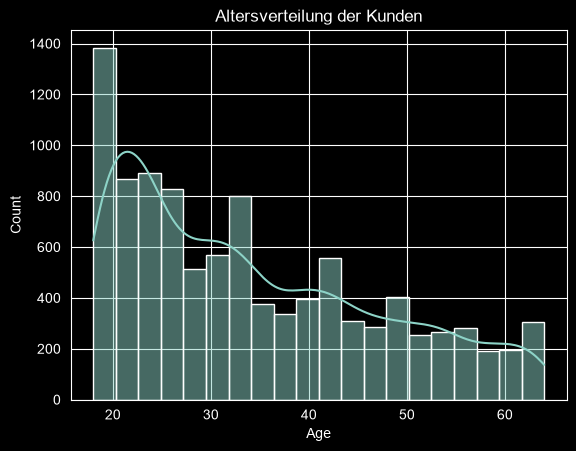

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(data=data, x="Age", bins=20, kde=True)  # Altersverteilung
plt.title("Altersverteilung der Kunden")  # Diagrammtitel
plt.show()  # Diagramm anzeigen

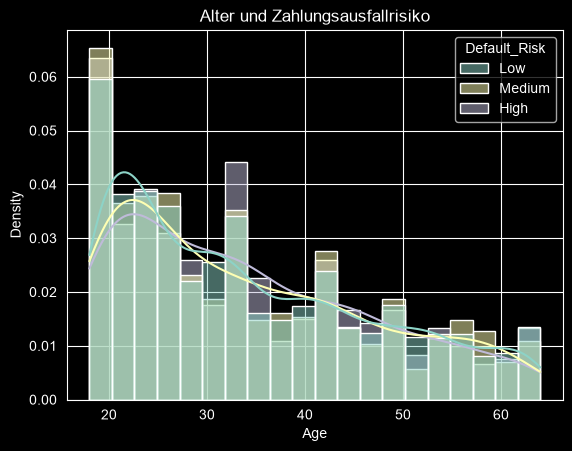

In [48]:
sns.histplot(
    data=data,
    x="Age",             # Feature: Alter
    hue="Default_Risk",  # Target: Zahlungsausfallrisiko
    bins=20,
    kde=True,
    stat="density",
    common_norm=False
)

plt.title("Alter und Zahlungsausfallrisiko")
plt.show()

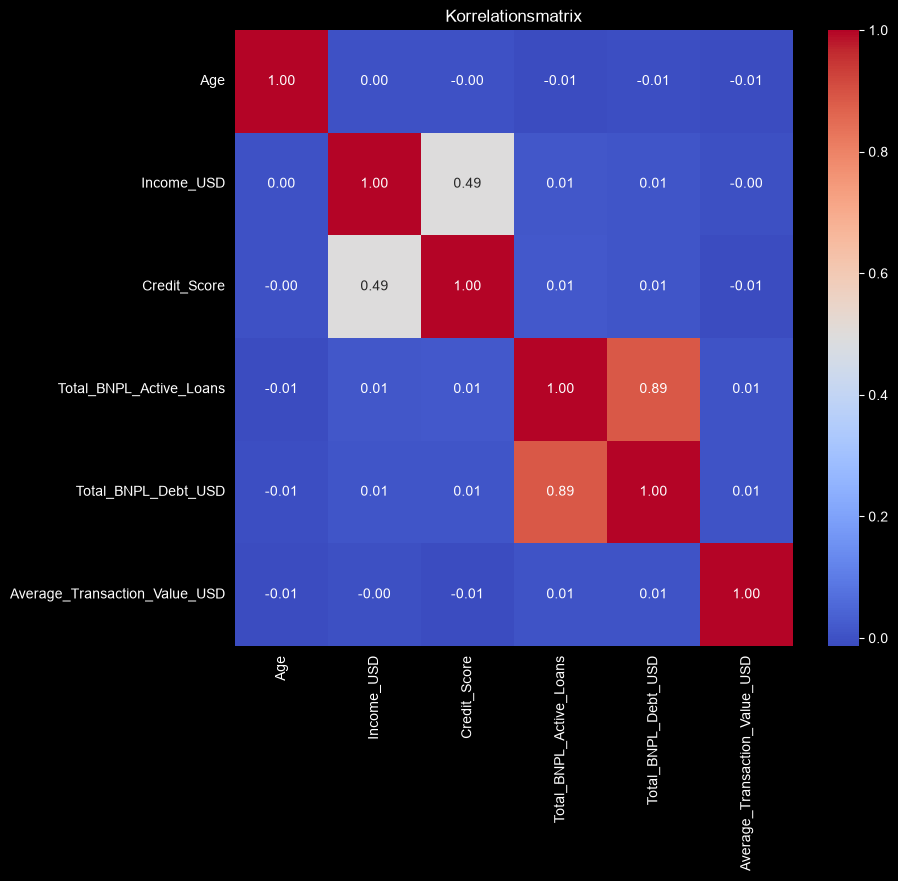

In [43]:
numeric_data = data.select_dtypes(include="number")# Numerische Spalten

plt.figure(figsize=(9, 8))  # Diagrammgröße

sns.heatmap(
    numeric_data.corr(),  # Korrelationen berechnen
    annot=True,           # Werte anzeigen
    cmap="coolwarm",      # Farbskala
    fmt=".2f"             # Zwei Nachkommastellen
)

plt.title("Korrelationsmatrix")  # Titel
plt.show()  # Diagramm anzeigen

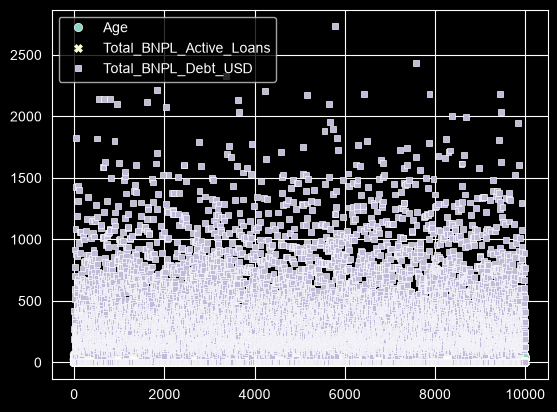

In [52]:
features = [
    "Age",                      # Alter
    "Total_BNPL_Active_Loans",  # Anzahl aktiver BNPL-Kredite
    "Total_BNPL_Debt_USD"       # Gesamtschulden in USD
]

sns.plot(data[features].dropna())  # Beziehungen der Merkmale
plt.show()  # Diagramme anzeigen